# This notebook runs the simulation for the USA
Copied from Hugo folder, file with the same name.

Changes to make:
 - Look at different vaccination and quarantine rates
 - Look at numerical errors in our estimations


In [7]:
from diffrax import diffeqsolve, ODETerm, SaveAt, Tsit5
import jax, jax.numpy as jnp
import matplotlib, matplotlib.pyplot as plt
import scienceplots
import numpy as np

import USA
from models import SEIR
from models import SIR
from models import SEIRD
from models import Parameters

plt.style.use([
    'science',
    #'no-latex'
    ])
plt.rcParams['text.latex.preamble'] = r'\usepackage{newtxmath, newtxtext}'
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=plt.cm.Set1.colors)

In [8]:
# General setup
solver = Tsit5() # choose method to solve differential equations. Default step size is ConstantStepSize()
y0 = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)
t0 = 0.0
t1 = 200.0
dt0 = 1.0 # step size
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0)) # when to save results, now set to every day

In [9]:
# Plot infectious population for different vaccination rates or quarantine factors
def plot_infection_peak(results, ts, parameter_name, figure_name, time_stop=110):
    mask = ts <= time_stop
    plt.figure()

    for parameter_value, ys in results.items():
        I_total = jnp.sum(ys[:, 2, :], axis=1)
        total_infected = np.trapezoid(np.asarray(I_total), x=np.asarray(ts))
        print(f"{parameter_name} = {parameter_value:.4f}: approximately {total_infected / 8:.0f} people")

        if parameter_name == "gamma":
            plt.plot(ts[mask], I_total[mask], label=fr"$\gamma = {parameter_value:.4f}$")
        elif parameter_name == "quarantine_factor":
            plt.plot(ts[mask], I_total[mask], label=fr"Q_f $= {parameter_value:.2f}$")
        else:
            plt.plot(ts[mask], I_total[mask], label=fr"{parameter_name}$= {parameter_value:.3f}$")

    plt.xlim(0, time_stop)
    plt.xlabel("Time (days)")
    plt.ylabel("Number of infected people")
    plt.legend()
    plt.savefig(figure_name)

In [10]:
# Plot infectious population for one county across different parameter values
def plot_infection_peak_one_county(results, ts, parameter_name, county_index, figure_name, time_stop=100):
    mask = ts <= time_stop
    plt.figure()

    for parameter_value, ys in results.items():
        I_county = ys[:, 2, county_index]
        total_infected = np.trapezoid(np.asarray(I_county), x=np.asarray(ts))
        print(f"{parameter_name} = {parameter_value:.3f}: approximately {total_infected / 8:.0f} people")
        label = fr"{parameter_name} = {parameter_value:.3f}"
        plt.plot(ts[mask], I_county[mask], label=label)

    plt.xlim(0, time_stop)
    plt.xlabel("Time (days)")
    plt.ylabel("Infectious population")
    plt.title(f"County index {county_index}")
    plt.legend()
    plt.savefig(figure_name)

## Vaccination rates

In [11]:
gamma_values = jnp.linspace(0.0, 0.01, 5) 
results_v = {} # store solutions in this dictionary

for gamma in gamma_values:
    # R0 = 12-18
    # contagious period ~ 8 days
    p = Parameters(alpha=1/9, beta=12/9, gamma=float(gamma), delta=1/11, W=USA.get_od_matrix(), quarantine_factor=0.75)

    solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
    
    ys = solution.ys.reshape((-1, 4, p.n_cities))
    results_v[float(gamma)] = ys # save simulation results

    print(f"gamma = {float(gamma):.5f}, solver stats = {solution.stats}")

ts = solution.ts

gamma = 0.00000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00250, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00500, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.00750, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
gamma = 0.01000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(

gamma = 0.0000: approximately 372665536 people
gamma = 0.0025: approximately 303956531 people
gamma = 0.0050: approximately 240602182 people
gamma = 0.0075: approximately 182223270 people
gamma = 0.0100: approximately 127952179 people


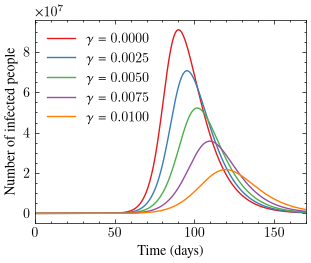

In [16]:
plot_infection_peak(results_v, ts, "gamma", "../figures/vaccination_rates.pdf", time_stop=170)

Comment on total number of people infected: This is just a rough estimate. Recovery rate is 1/8, therefore I am dividing total person-days with 8 to get the approximate amount of individual people who have been sick for each vaccination rate. A better but more complicated way of calculating this would be to look at the infection rate instead. I think this is good enough, it shows that vaccination not only pushes the peak forward but also decrease the total number of people who get the disease. 

## Quarantine

In [18]:
quarantinue_factor_values = [0, 0.5, 0.9, 0.99]
results_q = {} # store solutions in this dictionary

for quarantine_factor in quarantinue_factor_values:
    # R0 = 12-18
    # contagious period ~ 8 days
    p = Parameters(alpha=1/9, beta=12/9, gamma=0, delta=1/11, W=USA.get_od_matrix(), quarantine_factor=quarantine_factor)
    

    solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
    
    ys = solution.ys.reshape((-1, 4, p.n_cities))
    results_q[float(quarantine_factor)] = ys # save simulation results

    print(f"quarantine factor = {float(quarantine_factor):.5f}, solver stats = {solution.stats}")

ts = solution.ts

quarantine factor = 0.00000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
quarantine factor = 0.50000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
quarantine factor = 0.90000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}
quarantine factor = 0.99000, solver stats = {'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}


quarantine_factor = 0.0000: approximately 372672474 people
quarantine_factor = 0.5000: approximately 372670364 people
quarantine_factor = 0.9000: approximately 372653910 people
quarantine_factor = 0.9900: approximately 372578149 people


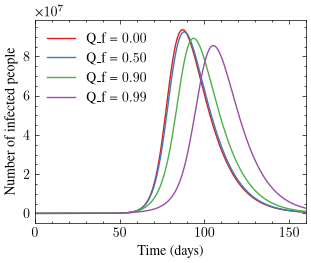

In [21]:
plot_infection_peak(results_q, ts, "quarantine_factor", "../figures/quarantine_factors.pdf", time_stop=160)

## Estimate numerical errors
Look at:
1) Make plot showing constant population size
2) Adjust time steps, look at a few different metrics to see that nothing important in our results change. Do this using different sizes of fixed time steps or alternatively (if time) adjusted time steps. 
     - Sum of the USA: When infectious peak occurs
     - Randomly select 2 cities/counties: When infection peak occurs

### 1. Check constant population size

In [22]:
# Run one basic simulation with set parameters
p = Parameters(alpha=1/9, beta=12/9, gamma=0, delta = 1/11, W=USA.get_od_matrix(), quarantine_factor=0.75)
solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
print(solution.stats)
ts = solution.ts
ys = solution.ys.reshape((-1, 4, p.n_cities)) # type: ignore

{'max_steps': 4096, 'num_accepted_steps': Array(200, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(200, dtype=int64, weak_type=True)}


Maximum difference between total population size: 1.1920928955078125e-07


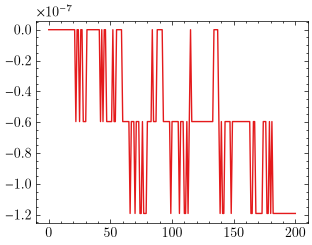

In [24]:
# Calculate total population size
S = ys[:, 0, :]
E = ys[:, 1, :]
I = ys[:, 2, :]
R = ys[:, 3, :]

N = S + E + I + R
N_total = jnp.sum(N, axis=1)

# Plot and print differences in poulation size over time
plt.figure()
plt.plot(ts, N_total-N_total[0])

max_difference = jnp.max(N_total) - jnp.min(N_total)
print(f"Maximum difference between total population size: {max_difference}")

### 2. Check numerical errors using different step sizes in solver

In [25]:
step_sizes = [0.125, 0.25, 0.5, 1, 2]
results_s = {} # store solutions in this dictionary

for step_size in step_sizes:
    # R0 = 12-18
    # contagious period ~ 8 days
    #solver = Tsit5() # Default ConstantStepSize(), used in the setup of this notebook
    p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.9**(1/365), delta=1/11, W=USA.get_od_matrix(), quarantine_factor=0.75)

    solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=float(step_size), y0=y0, args=p, saveat=saveat) # dt0 controls step size (Initial step size the solver tries)
    
    ys = solution.ys.reshape((-1, 4, p.n_cities))
    results_s[float(step_size)] = ys # save simulation results

    print(f"step size = {float(step_size):.5f}, solver stats = {solution.stats}")

ts = solution.ts

KeyboardInterrupt: 

step_size = 0.1250: approximately 325360909 people
step_size = 0.2500: approximately 325360909 people
step_size = 0.5000: approximately 325360909 people
step_size = 1.0000: approximately 325360923 people
step_size = 2.0000: approximately 325360940 people
step_size = 0.125: approximately 57681 people
step_size = 0.250: approximately 57681 people
step_size = 0.500: approximately 57681 people
step_size = 1.000: approximately 57681 people
step_size = 2.000: approximately 57681 people


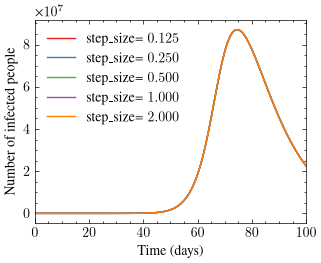

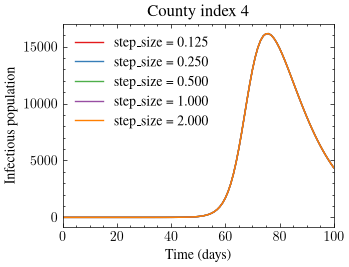

In [82]:
plot_infection_peak(results_s, ts, "step_size", "../figures/total_USA_error.pdf", time_stop=100)
plot_infection_peak_one_county(results_s, ts, "step_size", county_index=4, figure_name="../figures/county_error.pdf", time_stop=100)

In [60]:
# Looking at the total infection curve
reference = jnp.sum(results_s[0.125][:, 2, :], axis=1)

for step_size, ys in results_s.items():
    I_total = jnp.sum(ys[:, 2, :], axis = 1)
    difference = jnp.abs(I_total - reference)
    print(f"Step size = {step_size}: max difference = {jnp.max(difference):.4f}, MAE = {jnp.mean(difference):.4f}")

N_total = jnp.max(reference)
print(f"\nTotal number of infected people in the simulation: {jnp.max(N_total):.0f}")
print(f"Ration of biggest error (error/total): {jnp.max(difference)/jnp.max(N_total)}")

Step size = 0.125: max difference = 0.0000, MAE = 0.0000
Step size = 0.25: max difference = 0.0324, MAE = 0.0038
Step size = 0.5: max difference = 0.5407, MAE = 0.0605
Step size = 1.0: max difference = 11.8830, MAE = 1.7900
Step size = 2.0: max difference = 2269.1152, MAE = 232.0305

Total number of infected people in the simulation: 87060121
Ration of biggest error (error/total): 2.6063773120128126e-05


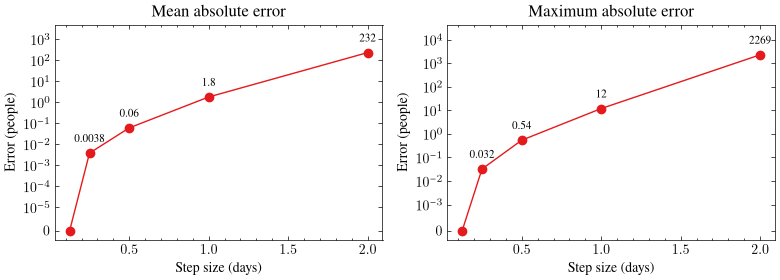

In [61]:
reference = jnp.sum(results_s[0.125][:, 2, :], axis=1)
step_sizes, max_errors, mean_errors = [], [], []

for step_size, ys in sorted(results_s.items()):
    I_total = jnp.sum(ys[:, 2, :], axis=1)
    difference = jnp.abs(I_total - reference)
    step_sizes.append(float(step_size))
    max_errors.append(float(jnp.max(difference)))
    mean_errors.append(float(jnp.mean(difference)))

fig, axes = plt.subplots(1, 2, figsize=(8, 3))

for ax, errors, title in zip(
    axes,
    [mean_errors, max_errors],
    ["Mean absolute error", "Maximum absolute error"]
):
    ax.plot(step_sizes, errors, marker="o")
    ax.set_yscale("symlog", linthresh=1e-5 if title.startswith("Mean") else 1e-3)
    ax.set_xlabel("Step size (days)")
    ax.set_ylabel("Error (people)")
    ax.set_title(title)

    for i, (x, y) in enumerate(zip(step_sizes, errors)):
        if i == 0:
            continue
        if i == 4:
            ax.annotate(f"{y:.0f}", (x, y), xytext=(0, 8),
            textcoords="offset points", ha="center", fontsize=8)
            continue
        ax.annotate(f"{y:.2g}", (x, y), xytext=(0, 8),
                    textcoords="offset points", ha="center", fontsize=8)
    
    ax.set_ylim(top=ax.get_ylim()[1] * 8) # Get extra space on the top

fig.tight_layout()
plt.savefig("../figures/USA_log_error.pdf")

In [62]:
# Looking at one randomly chosen county
county_index = np.random.randint(results_s[0.125].shape[2])
reference = results_s[0.125][:, 2, county_index]

print(f"Randomly chosen county index: {county_index}")

for step_size, ys in results_s.items():
    I_county = ys[:, 2, county_index]
    difference = jnp.abs(I_county - reference)
    print(f"Step size = {step_size}: max difference = {jnp.max(difference):.6f}, MAE = {jnp.mean(difference):.6f}")

N_total = jnp.max(reference)
print(f"\nMaximum infectious population in this county: {N_total:.0f}")
print(f"Ratio of biggest error (error/maximum infectious population): {jnp.max(difference) / N_total:}")

Randomly chosen county index: 45
Step size = 0.125: max difference = 0.000000, MAE = 0.000000
Step size = 0.25: max difference = 0.000002, MAE = 0.000000
Step size = 0.5: max difference = 0.000036, MAE = 0.000004
Step size = 1.0: max difference = 0.001013, MAE = 0.000121
Step size = 2.0: max difference = 0.174779, MAE = 0.014865

Maximum infectious population in this county: 5046
Ratio of biggest error (error/maximum infectious population): 3.463761260936855e-05


## Make line plots for the different types of models (SIR and SEIR)

In [5]:
# Shared parameters
dt0 = 1
t1=150
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0)) # when to save results, now set to every day
W = USA.get_od_matrix()
p = Parameters(alpha=1/9, beta=12/9, gamma=0, delta=1/11, cfr=0.002, W=W, quarantine_factor=0.75)

# Initial conditions
y0_seir = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)
S0, E0, I0, R0 = y0_seir.reshape(4, -1)
y0_sir = jnp.concatenate([S0, I0, R0])
y0_seird = jnp.concatenate([S0, E0, I0, R0, jnp.zeros_like(S0)])

# Run all three simulations
sol_sir = diffeqsolve(SIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0_sir, args=p, saveat=saveat)
sol_seir = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0_seir, args=p, saveat=saveat)
sol_seird = diffeqsolve(SEIRD, solver, t0=t0, t1=t1, dt0=dt0, y0=y0_seird, args=p, saveat=saveat)

# Reshape solutions
ys_sir = sol_sir.ys.reshape((-1, 3, p.n_cities))
ys_seir = sol_seir.ys.reshape((-1, 4, p.n_cities))
ys_seird = sol_seird.ys.reshape((-1, 5, p.n_cities))
ts = sol_seir.ts

# Sum each compartment over all counties
sir_S, sir_I, sir_R = [jnp.sum(ys_sir[:, i, :], axis=1) for i in range(3)]
seir_S, seir_E, seir_I, seir_R = [jnp.sum(ys_seir[:, i, :], axis=1) for i in range(4)]
seird_S, seird_E, seird_I, seird_R, seird_D = [jnp.sum(ys_seird[:, i, :], axis=1) for i in range(5)]

# Shared colours
colors = {"S": "red", "E": "purple", "I": "blue", "R": "green", "D": "orange"}
"""
# SIR plot
plt.figure()
plt.plot(sol_sir.ts, sir_S, label="S", color=colors["S"])
plt.plot(sol_sir.ts, sir_I, label="I", color=colors["I"])
plt.plot(sol_sir.ts, sir_R, label="R", color=colors["R"])
plt.xlabel("t [day]")
plt.ylabel("Number of people")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/SIR.pdf")
plt.show()

# SEIR plot
plt.figure()
plt.plot(sol_seir.ts, seir_S, label="S", color=colors["S"])
plt.plot(sol_seir.ts, seir_E, label="E", color=colors["E"])
plt.plot(sol_seir.ts, seir_I, label="I", color=colors["I"])
plt.plot(sol_seir.ts, seir_R, label="R", color=colors["R"])
plt.xlabel("t [day]")
plt.ylabel("Number of people")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/SEIR.pdf")
plt.show()

# SEIRD plot
plt.figure()
plt.plot(sol_seird.ts, seird_S, label="S", color=colors["S"])
plt.plot(sol_seird.ts, seird_E, label="E", color=colors["E"])
plt.plot(sol_seird.ts, seird_I, label="I", color=colors["I"])
plt.plot(sol_seird.ts, seird_R, label="R", color=colors["R"])
plt.plot(sol_seird.ts, seird_D, label="D", color=colors["D"])
plt.xlabel("t [day]")
plt.ylabel("Number of people")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/SEIRD.pdf")
plt.show()"""

'\n# SIR plot\nplt.figure()\nplt.plot(sol_sir.ts, sir_S, label="S", color=colors["S"])\nplt.plot(sol_sir.ts, sir_I, label="I", color=colors["I"])\nplt.plot(sol_sir.ts, sir_R, label="R", color=colors["R"])\nplt.xlabel("t [day]")\nplt.ylabel("Number of people")\nplt.legend()\nplt.tight_layout()\nplt.savefig("../figures/SIR.pdf")\nplt.show()\n\n# SEIR plot\nplt.figure()\nplt.plot(sol_seir.ts, seir_S, label="S", color=colors["S"])\nplt.plot(sol_seir.ts, seir_E, label="E", color=colors["E"])\nplt.plot(sol_seir.ts, seir_I, label="I", color=colors["I"])\nplt.plot(sol_seir.ts, seir_R, label="R", color=colors["R"])\nplt.xlabel("t [day]")\nplt.ylabel("Number of people")\nplt.legend()\nplt.tight_layout()\nplt.savefig("../figures/SEIR.pdf")\nplt.show()\n\n# SEIRD plot\nplt.figure()\nplt.plot(sol_seird.ts, seird_S, label="S", color=colors["S"])\nplt.plot(sol_seird.ts, seird_E, label="E", color=colors["E"])\nplt.plot(sol_seird.ts, seird_I, label="I", color=colors["I"])\nplt.plot(sol_seird.ts, seird_

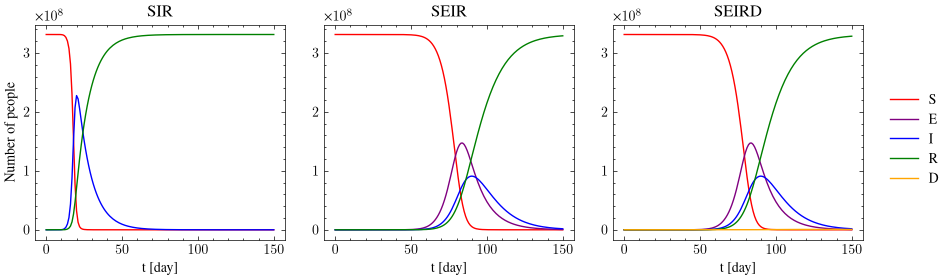

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3))

# SIR
axes[0].plot(sol_sir.ts, sir_S, label="S", color=colors["S"])
axes[0].plot(sol_sir.ts, sir_I, label="I", color=colors["I"])
axes[0].plot(sol_sir.ts, sir_R, label="R", color=colors["R"])
axes[0].set_title("SIR")
axes[0].set_xlabel("t [day]")
axes[0].set_ylabel("Number of people")
#axes[0].legend()

# SEIR
axes[1].plot(sol_seir.ts, seir_S, label="S", color=colors["S"])
axes[1].plot(sol_seir.ts, seir_E, label="E", color=colors["E"])
axes[1].plot(sol_seir.ts, seir_I, label="I", color=colors["I"])
axes[1].plot(sol_seir.ts, seir_R, label="R", color=colors["R"])
axes[1].set_title("SEIR")
axes[1].set_xlabel("t [day]")
#axes[1].set_ylabel("Number of people")
#axes[1].legend()

# SEIRD
axes[2].plot(sol_seird.ts, seird_S, label="S", color=colors["S"])
axes[2].plot(sol_seird.ts, seird_E, label="E", color=colors["E"])
axes[2].plot(sol_seird.ts, seird_I, label="I", color=colors["I"])
axes[2].plot(sol_seird.ts, seird_R, label="R", color=colors["R"])
axes[2].plot(sol_seird.ts, seird_D, label="D", color=colors["D"])
axes[2].set_title("SEIRD")
axes[2].set_xlabel("t [day]")
#axes[2].set_ylabel("Number of people")
#axes[2].legend()

# Shared legend on the right
handles, labels = axes[2].get_legend_handles_labels()
fig.legend(handles, labels, loc="center right", bbox_to_anchor=(1.08, 0.5))

plt.tight_layout()
plt.savefig("../figures/model_comparison.pdf")
plt.show()

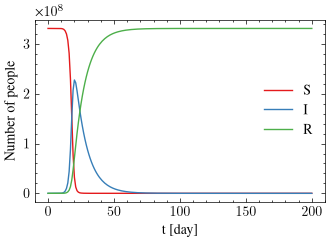

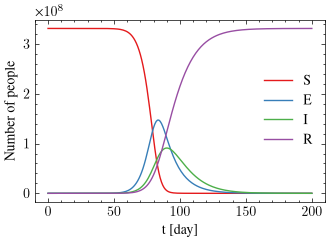

In [14]:
# Reduce over counties
sir_S, sir_I, sir_R = [jnp.sum(ys_sir[:, i, :], axis=1) for i in range(3)]
seir_S, seir_E, seir_I, seir_R = [jnp.sum(ys_seir[:, i, :], axis=1) for i in range(4)]

# SIR plot
plt.figure()
plt.plot(sol_sir.ts, sir_S, label="S")
plt.plot(sol_sir.ts, sir_I, label="I")
plt.plot(sol_sir.ts, sir_R, label="R")
plt.xlabel("t [day]")
plt.ylabel("Number of people")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/SIR.pdf")
plt.show()

# SEIR plot
plt.figure()
plt.plot(sol_seir.ts, seir_S, label="S")
plt.plot(sol_seir.ts, seir_E, label="E")
plt.plot(sol_seir.ts, seir_I, label="I")
plt.plot(sol_seir.ts, seir_R, label="R")
plt.xlabel("t [day]")
plt.ylabel("Number of people")
plt.legend()
plt.tight_layout()
plt.savefig("../figures/SEIR.pdf")
plt.show()

## Old code copied from original file

In [85]:
# R0 = 12-18
# contagious period ~ 8 days
p = Parameters(alpha=1/8, beta=15/8, gamma=1 - 0.9**(1/365), delta = 1/11, W=USA.get_od_matrix(), quarantine_factor=0.75)
solver = Tsit5()

y0 = USA.make_initial_condition(initial_county=36047, initial_vaccination_rate=0.0)

In [86]:
t0 = 0.0
t1 = 100.0
dt0 = 1.0
saveat = SaveAt(ts=jnp.arange(t0, t1+dt0, dt0))

In [87]:
solution = diffeqsolve(SEIR, solver, t0=t0, t1=t1, dt0=dt0, y0=y0, args=p, saveat=saveat)
print(solution.stats)

{'max_steps': 4096, 'num_accepted_steps': Array(100, dtype=int64, weak_type=True), 'num_rejected_steps': Array(0, dtype=int64, weak_type=True), 'num_steps': Array(100, dtype=int64, weak_type=True)}


In [88]:
ts = solution.ts
ys = solution.ys.reshape((-1, 4, p.n_cities)) # type: ignore

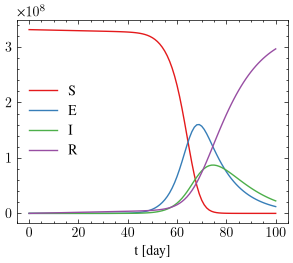

In [89]:
# plot S, E, I, R reduced over counties
plt.figure()
S_reduced = jnp.sum(ys[:, 0, :], axis=1)
E_reduced = jnp.sum(ys[:, 1, :], axis=1)
I_reduced = jnp.sum(ys[:, 2, :], axis=1)
R_reduced = jnp.sum(ys[:, 3, :], axis=1)
plt.plot(ts, S_reduced, label="S")
plt.plot(ts, E_reduced, label="E")
plt.plot(ts, I_reduced, label="I")
plt.plot(ts, R_reduced, label="R")
plt.xlabel("t [day]")
plt.legend()
plt.savefig("../figures/SEIR.pdf")

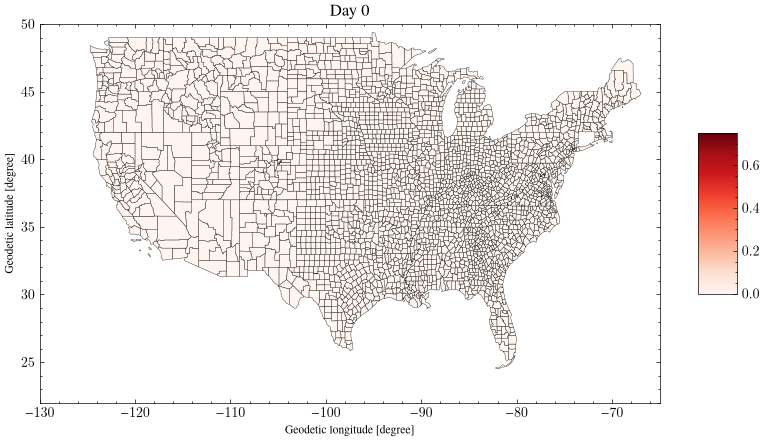

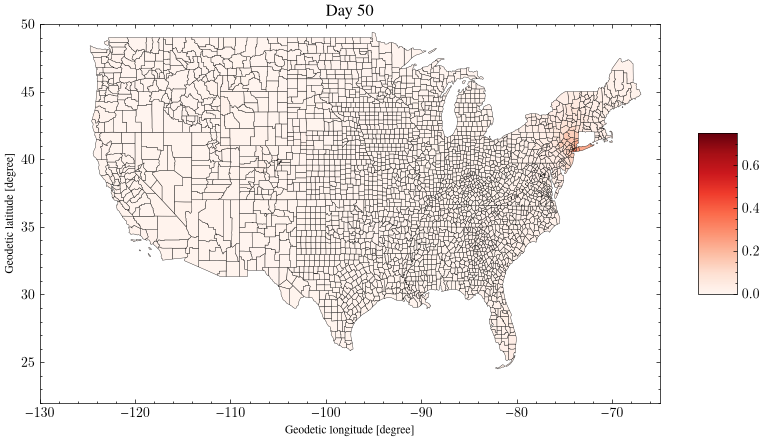

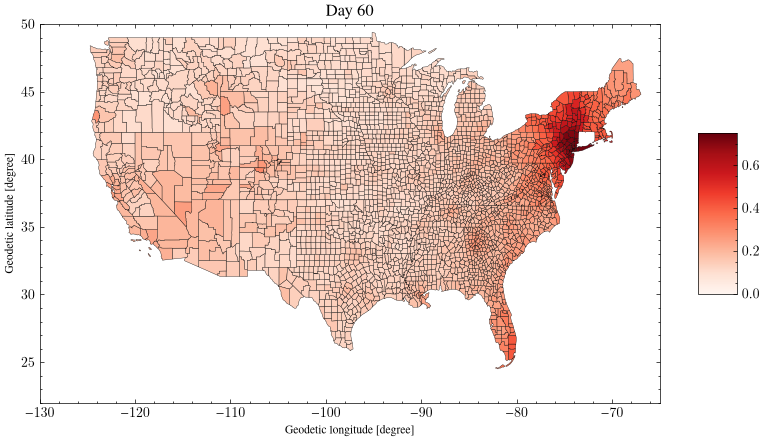

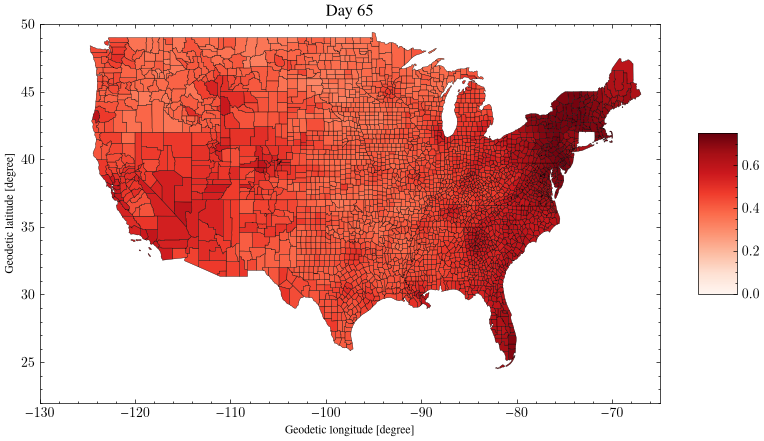

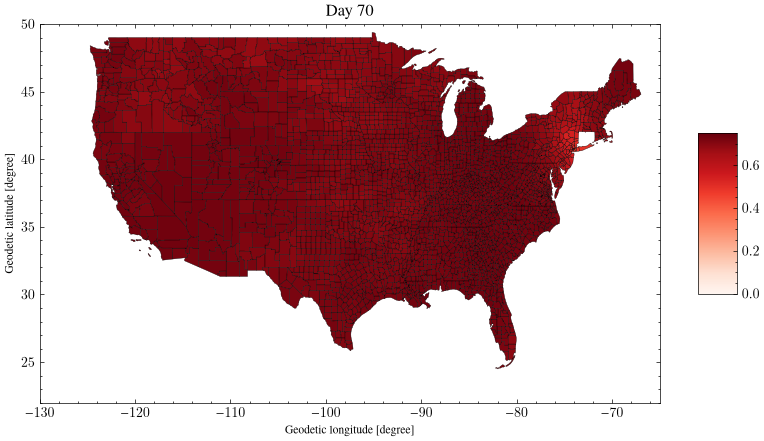

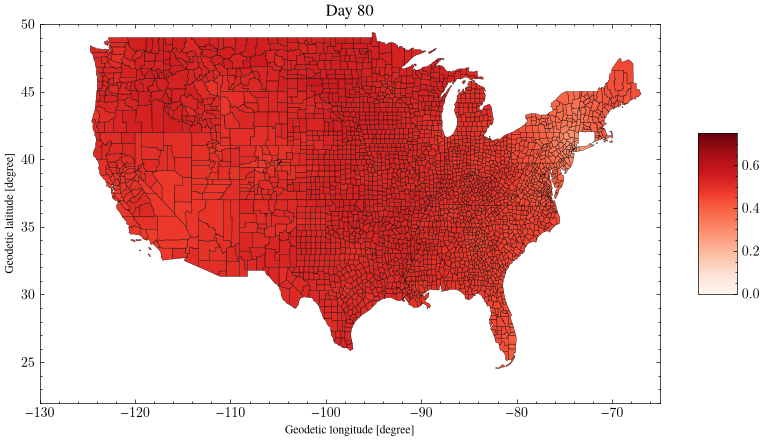

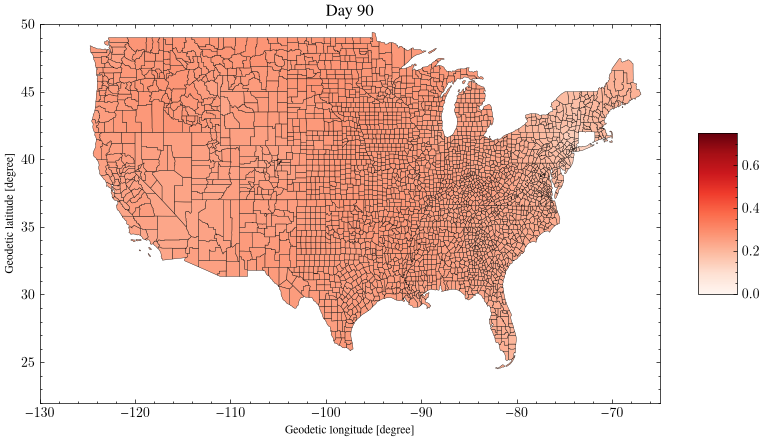

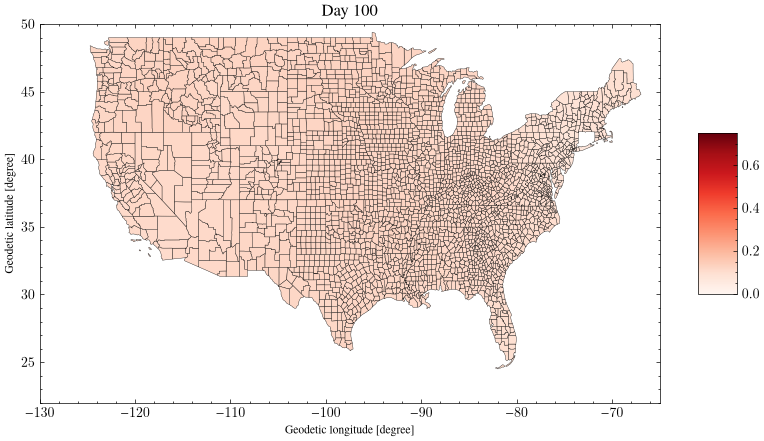

In [90]:
for day in [0, 50, 60, 65, 70, 80, 90, 100]:
    gdf = USA.get_gdf()
    plt.figure(figsize=(10,10))
    plt.title(f"Day {day}")
    S, E, I, R = ys[day, :, :]
    gdf['infected'] = (E + I) / (S + E + I + R)
    gdf.plot(column='infected', ax=plt.gca(), legend=True, cmap='Reds', edgecolor='black', linewidth=0.25, vmin=0, vmax=0.75)
    plt.xlim([-130, -65])
    plt.ylim([22, 50])
    plt.show()